# 03 · Probing: is "injection" in the activations?

The question: **can a linear probe read "this text is a prompt injection" off SmolLM2's residual stream — and at which layer?**

Recipe: get activations for every text at every layer → train one probe per layer → compare with a shuffled-label control and a length-only baseline.

In [1]:
# On Colab, uncomment and run these three lines first:
# !git clone <repo-url>
# %cd rig-interpretability-hackathon/starter/notebooks
# !pip install -q -r ../requirements.txt

import sys; sys.path.insert(0, "..")      # so the helper files in starter/ import
import numpy as np
import matplotlib.pyplot as plt
from lm import load_model, get_activations
from data import load_injections
from probes import layer_sweep, best_layer, train_probe

model, tok = load_model()
train_texts, train_y = load_injections("train")
test_texts, test_y = load_injections("test")

In [2]:
acts_train = get_activations(model, tok, train_texts)      # ~1 minute on CPU
acts_test = get_activations(model, tok, test_texts)
print("shape:", acts_train.shape, "= (texts, layers + 1, d_model)")

shape: (546, 31, 576) = (texts, layers + 1, d_model)


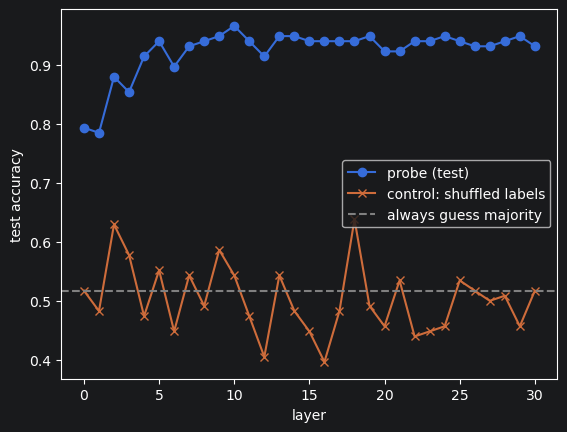

best layer: 10   test acc 0.97   AUROC 0.98


In [3]:
sweep = layer_sweep(acts_train, train_y, acts_test, test_y)
layers = [r["layer"] for r in sweep]
plt.plot(layers, [r["test_acc"] for r in sweep], marker="o", label="probe (test)")
plt.plot(layers, [r["control_acc"] for r in sweep], marker="x", label="control: shuffled labels")
plt.axhline(max(test_y.mean(), 1 - test_y.mean()), ls="--", c="grey", label="always guess majority")
plt.xlabel("layer"); plt.ylabel("test accuracy"); plt.legend(); plt.show()

L = best_layer(sweep)
print(f"best layer: {L}   test acc {sweep[L]['test_acc']:.2f}   AUROC {sweep[L]['auroc']:.2f}")

## The baseline that keeps you honest

A probe on *text length alone*. If it does nearly as well as the activation probe, the activations may just be encoding length.

In [4]:
len_tr = np.array([[len(t)] for t in train_texts]); len_te = np.array([[len(t)] for t in test_texts])
print(f"length-only probe: acc {train_probe(len_tr, train_y, len_te, test_y)['test_acc']:.2f}")
print(f"activation probe:  acc {sweep[L]['test_acc']:.2f}  (layer {L})")

length-only probe: acc 0.62
activation probe:  acc 0.97  (layer 10)


**Reading the plot.** Layer 0 is just the token embeddings, so whatever it gets is word-level evidence. A rise in the middle layers means the model builds a more abstract representation there. The control should hug 50%.

`best_layer` picks from layers ≥ 1, because notebook 04 steers at that layer and you can't steer the embeddings. If layer 0 scores as well as anything else, the two classes are separable by their *words* alone — note that in your write-up.

We save the activations so notebook 04 doesn't have to recompute them.

In [5]:
np.savez("acts_injections.npz", train=acts_train, test=acts_test,
         train_y=train_y, test_y=test_y, best_layer=L)
print("saved acts_injections.npz")

saved acts_injections.npz


Next: **04 · Steering** — is the direction we found actually used?